# 🌌 Sistema de Reconhecimento de EPBs usando 2DPCA e Cascata de Qualidade de Céu — V4.0

## Equatorial Plasma Bubbles Detection System — Two-Stage Pipeline

### 🎯 Novidades da Versão 4.0:
Esta versão introduz a **Arquitetura em Cascata (Two-Stage Pipeline)** para resolver o problema clássico de falsos positivos em **fotos nubladas / encobertas**:

- 🛡️ **Estágio 1: Controle de Qualidade Físico-Óptico (Troposfera < 12 km)**
  - Detecção de estrelas (fontes pontuais de alta frequência via filtro passa-alta)
  - Análise fotométrica de brilho e variância bruta pré-CLAHE
  - Bloqueio de inferência para céus nublados / obscurecidos, impedindo que o CLAHE gere artefatos artificiais parecidos com bolhas
- 🚀 **Estágio 2: Reconhecimento Ionosférico de EPBs (Ionosfera ~250–300 km)**
  - **2DPCA** (Two-Dimensional PCA) com 5 componentes espaciais
  - **SMOTE** para balanceamento da classe minoritária
  - **Stacking Classifier** (SVM RBF + XGBoost + Random Forest com Meta-LogisticRegression)
- 📊 **Avaliação Integrada:**
  - Validação cruzada (F1-score ~100% em céu limpo)
  - Benchmark em noites reais: céu nublado (`CA_20260624`), céu com EPB (`CA_20251022`) e céu quieto (`BJL_20250722`)

---
**Autor:** Alberto Ivo da Costa Vieira

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from epb_detection_system import (
    load_epb_dataset, augment_epb_data, EPBRecognitionSystem,
    EPBModelData, save_model, load_model,
    plot_comprehensive_analysis, explain_feature_importance,
    analyze_threshold_sensitivity, plot_calibration_analysis,
    evaluate_kfold_cv, benchmark_baselines,
    explain_shap_importance, setup_logging,
    assess_sky_quality, detect_stars, predict_with_qc,
    analyze_temporal_sequence
)

setup_logging()

In [2]:
# ========== CONFIGURAÇÕES ==========\
DATA_FOLDER = 'data/all-images'         # Pasta com todas as imagens
LABEL_FILE = 'data/epb_labels.csv'      # CSV com labels

TARGET_SIZE = (64, 64)           # Tamanho das imagens
AUGMENT_FACTOR = 3               # Fator de aumento para data augmentation
BALANCE_METHOD = 'smote'         # 'smote', 'undersample', ou 'combined'

# Hiperparâmetros fixos do modelo
N_COMPONENTS = 5                 # Componentes 2DPCA
ENSEMBLE_PARAMS = {
    'n_components': 5,
    'svm_C': 10.0,
    'svm_gamma': 'auto',
    'xgb_n_estimators': 100,
    'xgb_max_depth': 3,
    'xgb_learning_rate': 0.05,
    'rf_n_estimators': 100,
    'rf_max_depth': 10,
    'meta_C': 0.1,
}
MODEL_VERSION = '4.0'

In [3]:
# Seed global para reprodutibilidade
np.random.seed(42)

print("="*70)
print(f"🌌 SISTEMA DE RECONHECIMENTO DE EPBs — V{MODEL_VERSION}")
print("="*70)

# ========== ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO ==========
print("\n" + "="*70)
print("ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO")
print("="*70)

X, y, filenames = load_epb_dataset(
    data_folder=DATA_FOLDER,
    label_file=LABEL_FILE,
    target_size=TARGET_SIZE,
    apply_preprocessing=True
)

# Divisão estratificada
X_train, X_test, y_train, y_test, files_train, files_test = train_test_split(
    X, y, filenames, test_size=0.25, random_state=42, stratify=y
)

print(f"\n📦 Divisão estratificada:")
print(f"   • Treino: {len(X_train)} imagens (EPB: {int(y_train.sum())}, Sem EPB: {int(len(y_train) - y_train.sum())})")
print(f"   • Teste: {len(X_test)} imagens (EPB: {int(y_test.sum())}, Sem EPB: {int(len(y_test) - y_test.sum())})")

INFO: Carregando dataset de EPBs...
INFO: Labels carregados: 510 registros


🌌 SISTEMA DE RECONHECIMENTO DE EPBs — V4.0

ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO


INFO: 510 imagens carregadas com sucesso
INFO: Dimensão das imagens: 64x64
INFO: Distribuição das classes:
INFO:   EPBs detectados: 255 (50.0%)
INFO:   No EPB: 255 (50.0%)



📦 Divisão estratificada:
   • Treino: 382 imagens (EPB: 191, Sem EPB: 191)
   • Teste: 128 imagens (EPB: 64, Sem EPB: 64)


In [4]:
# ========== ETAPA 2: DATA AUGMENTATION ==========
if len(X_train) < 2000:
    print("="*70)
    print("ETAPA 2: DATA AUGMENTATION")
    print("="*70)

    X_train_aug, y_train_aug = augment_epb_data(X_train, y_train, augment_factor=AUGMENT_FACTOR)
else:
    X_train_aug, y_train_aug = X_train, y_train

INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 191 imgs (fator=x5)
INFO:   Classe 1: 191 imgs (fator=x3)
INFO: Dataset expandido: 382 → 1528 imagens (classe 0: 191→955, classe 1: 191→573)


ETAPA 2: DATA AUGMENTATION


In [5]:
# ========== ETAPA 3: TREINAMENTO DO SISTEMA COMPLETO ==========
print("="*70)
print("ETAPA 3: TREINAMENTO DO SISTEMA COMPLETO (2DPCA + SMOTE + ENSEMBLE)")
print("="*70)

system = EPBRecognitionSystem(
    n_components=N_COMPONENTS,
    balance_data=True,
    balance_method=BALANCE_METHOD,
    ensemble_params=ENSEMBLE_PARAMS,
)

system.fit(X_train_aug, y_train_aug)

INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...


ETAPA 3: TREINAMENTO DO SISTEMA COMPLETO (2DPCA + SMOTE + ENSEMBLE)


INFO: Variância explicada: 56.86%
INFO: Extraindo features...
INFO: Shape das features: (1528, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Usando hiperparâmetros otimizados do ensemble:
INFO:   n_components: 5
INFO:   svm_C: 10.0
INFO:   svm_gamma: auto
INFO:   xgb_n_estimators: 100
INFO:   xgb_max_depth: 3
INFO:   xgb_learning_rate: 0.05
INFO:   rf_n_estimators: 100
INFO:   rf_max_depth: 10
INFO:   meta_C: 0.1
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 955 → 955
INFO: Classe 1: 573 → 955
INFO: Treinamento concluído!


ETAPA 4: AVALIAÇÃO DE PERFORMANCE NO CONJUNTO DE TESTE

📊 Relatório de Classificação:
              precision    recall  f1-score   support

      No EPB     1.0000    1.0000    1.0000        64
         EPB     1.0000    1.0000    1.0000        64

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000    1.0000    1.0000       128



/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127756 (\N{MILKY WAY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


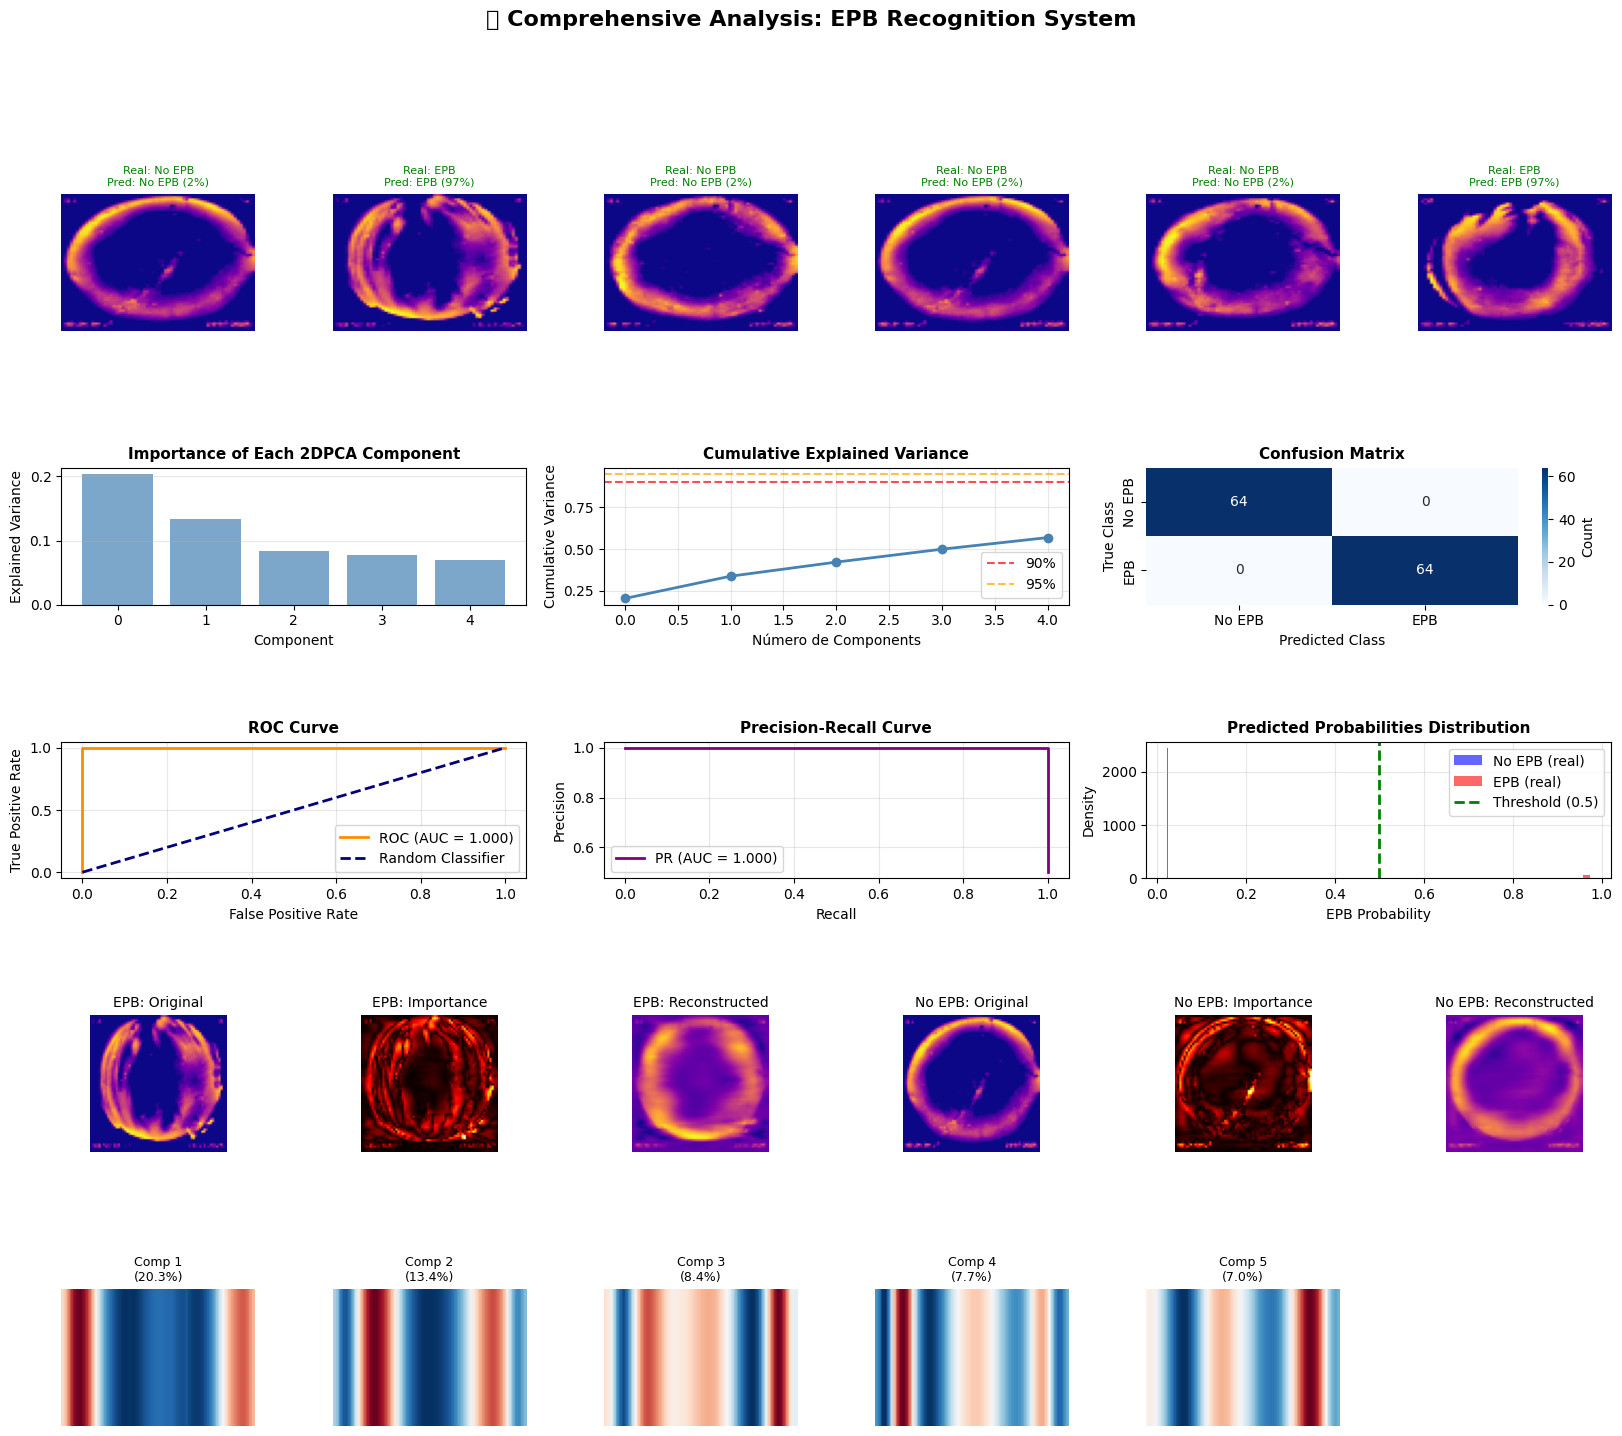

/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Glyph 127756 (\N{MILKY WAY}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)


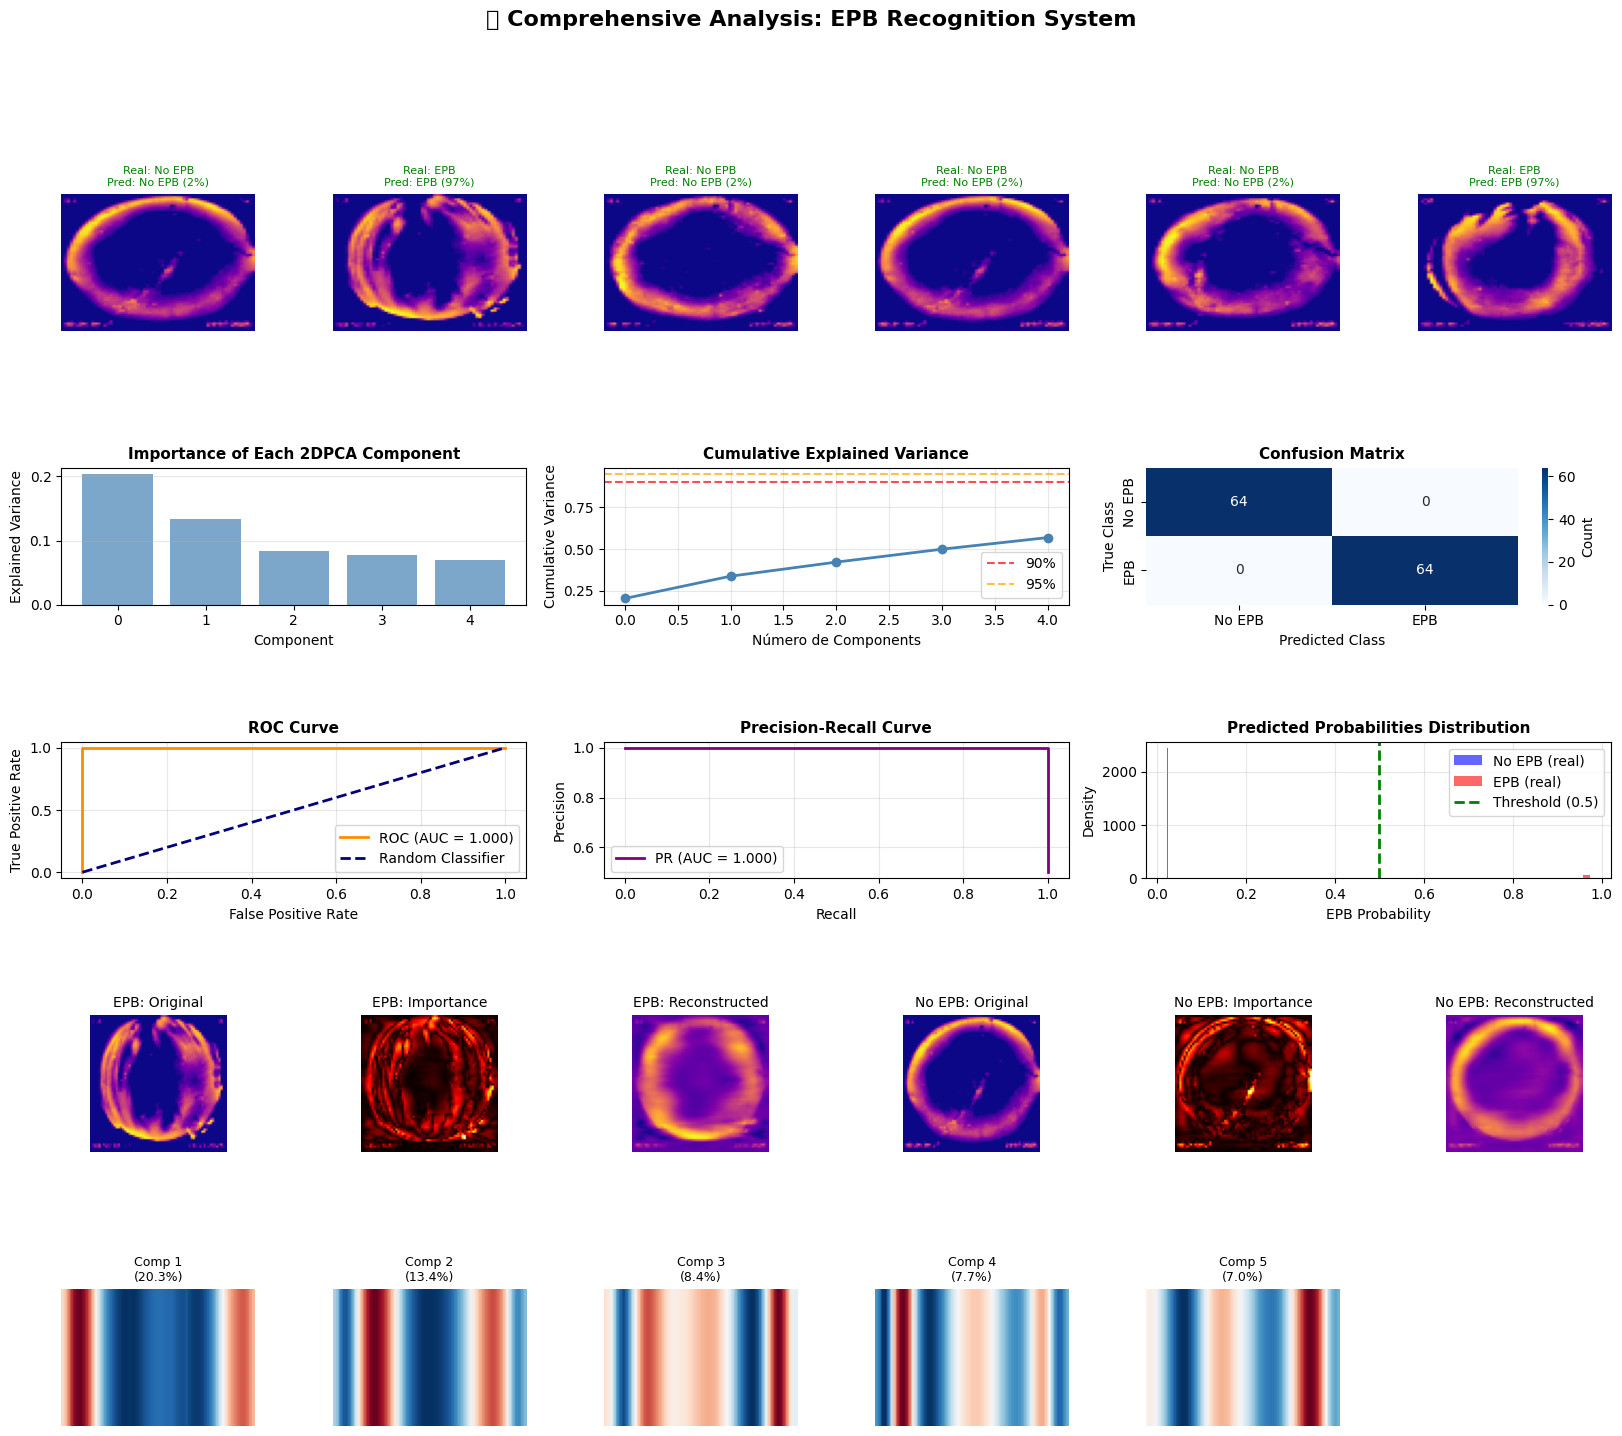

In [6]:
# ========== ETAPA 4: AVALIAÇÃO GLOBAL (TEST SET) ==========
print("="*70)
print("ETAPA 4: AVALIAÇÃO DE PERFORMANCE NO CONJUNTO DE TESTE")
print("="*70)

y_pred = system.predict(X_test)
y_proba = system.predict_proba(X_test)[:, 1]

print("\n📊 Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=['No EPB', 'EPB'], digits=4))

# Visualização abrangente
plot_comprehensive_analysis(system, X_train, X_test, y_train, y_test, y_pred, y_proba)

INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)
INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...


ETAPA 5: VALIDAÇÃO CRUZADA ESTRATIFICADA (5-FOLD CV)

📊 AVALIAÇÃO K-FOLD CROSS-VALIDATION (5 folds)
   Components: 5 | Balanceamento: smote
   Augmentation: Sim (fator=3)
   Total de amostras: 510 (255 EPB, 255 No EPB)



INFO: Variância explicada: 57.12%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Usando hiperparâmetros otimizados do ensemble:
INFO:   n_components: 5
INFO:   svm_C: 10.0
INFO:   svm_gamma: auto
INFO:   xgb_n_estimators: 100
INFO:   xgb_max_depth: 3
INFO:   xgb_learning_rate: 0.05
INFO:   rf_n_estimators: 100
INFO:   rf_max_depth: 10
INFO:   meta_C: 0.1
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)
INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...


   Fold 1/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


INFO: Variância explicada: 57.26%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Usando hiperparâmetros otimizados do ensemble:
INFO:   n_components: 5
INFO:   svm_C: 10.0
INFO:   svm_gamma: auto
INFO:   xgb_n_estimators: 100
INFO:   xgb_max_depth: 3
INFO:   xgb_learning_rate: 0.05
INFO:   rf_n_estimators: 100
INFO:   rf_max_depth: 10
INFO:   meta_C: 0.1
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)
INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)


   Fold 2/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


... (2 outputs left out)

INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 56.74%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Usando hiperparâmetros otimizados do ensemble:
INFO:   n_components: 5
INFO:   svm_C: 10.0
INFO:   svm_gamma: auto
INFO:   xgb_n_estimators: 100
INFO:   xgb_max_depth: 3
INFO:   xgb_learning_rate: 0.05
INFO:   rf_n_estimators: 100
INFO:   rf_max_depth: 10
INFO:   meta_C: 0.1
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)


   Fold 4/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 56.89%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Usando hiperparâmetros otimizados do ensemble:
INFO:   n_components: 5
INFO:   svm_C: 10.0
INFO:   svm_gamma: auto
INFO:   xgb_n_estimators: 100
INFO:   xgb_max_depth: 3
INFO:   xgb_learning_rate: 0.05
INFO:   rf_n_estimators: 100
INFO:   rf_max_depth: 10
INFO:   meta_C: 0.1
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2713: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=Fa

   Fold 5/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000

📈 RESULTADOS 5-FOLD CROSS-VALIDATION

   Metric                    Média      ± Std        Mín        Máx
   ------------------------------------------------------------
   Accuracy                 0.9980     0.0044     0.9902     1.0000
   Sensitivity              0.9961     0.0088     0.9804     1.0000
   Specificity              1.0000     0.0000     1.0000     1.0000
   Precision                1.0000     0.0000     1.0000     1.0000
   F1                       0.9980     0.0044     0.9901     1.0000
   Auc                      1.0000     0.0000     1.0000     1.0000

   💡 Para reportar na dissertação:
      F1-Score: 0.9980 ± 0.0044
      AUC:      1.0000 ± 0.0000
      Sens.:    0.9961 ± 0.0088


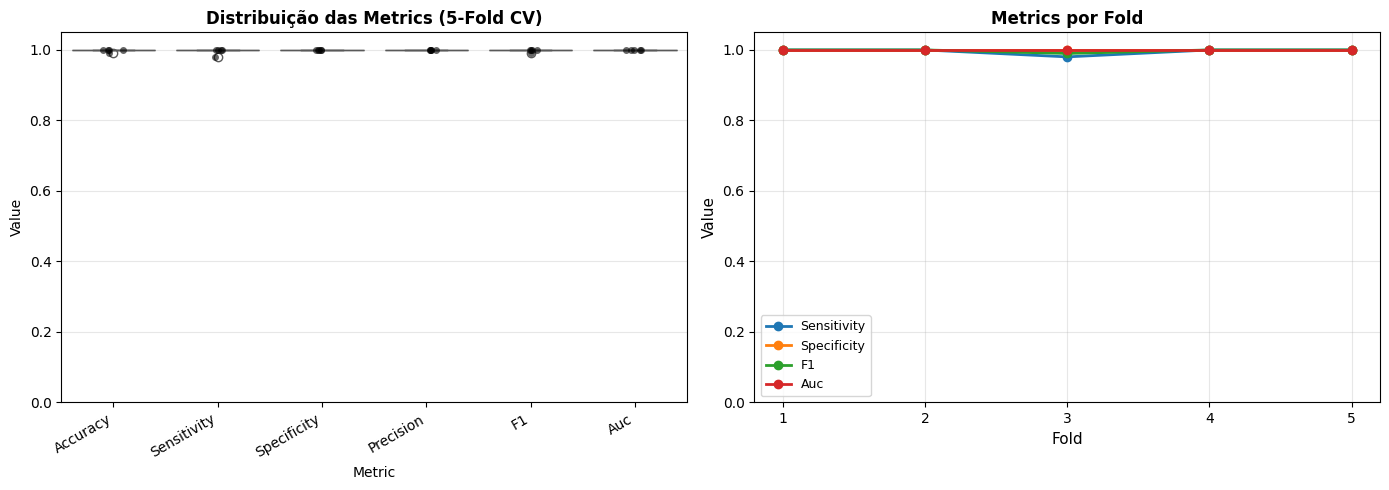

In [7]:
# ========== ETAPA 5: VALIDAÇÃO CRUZADA (5 FOLDS) ==========
print("="*70)
print("ETAPA 5: VALIDAÇÃO CRUZADA ESTRATIFICADA (5-FOLD CV)")
print("="*70)

cv_results = evaluate_kfold_cv(
    X=X, y=y,
    n_components=N_COMPONENTS,
    n_splits=5,
    balance_method=BALANCE_METHOD,
    ensemble_params=ENSEMBLE_PARAMS,
    random_state=42
)

In [8]:
# ========== ETAPA 6: BENCHMARK DO MÓDULO DE QUALIDADE DE CÉU (QC) ==========
print("="*70)
print("ETAPA 6: BENCHMARK DO FILTRO DE QUALIDADE DE CÉU (QC) NAS NOITES REAIS")
print("="*70)

import glob
from PIL import Image

def test_night_qc(folder_path, night_name, expected_type):
    files = sorted(glob.glob(f'{folder_path}/*.png'))
    if not files:
        print(f"⚠️  Nenhuma imagem encontrada em {folder_path}")
        return
    
    n_total = len(files)
    n_cloudy = 0
    n_epb_detected = 0
    n_quiet = 0
    
    for f in files:
        img_raw = np.array(Image.open(f).convert('L'))
        res = predict_with_qc(system, img_raw, target_size=TARGET_SIZE)
        if res.status == 'CLOUDY_OBSCURED':
            n_cloudy += 1
        elif res.has_epb == 1:
            n_epb_detected += 1
        else:
            n_quiet += 1
            
    print(f"\n🌃 Noite: {night_name} ({expected_type}) | Total de Imagens: {n_total}")
    print(f"   • Céu Nublado / Obstruído (Filtradas pelo QC): {n_cloudy} ({n_cloudy/n_total*100:.1f}%)")
    print(f"   • Céu Limpo com EPB Detectada:                 {n_epb_detected} ({n_epb_detected/n_total*100:.1f}%)")
    print(f"   • Céu Limpo Sem EPB (Quieto):                  {n_quiet} ({n_quiet/n_total*100:.1f}%)")
    if 'Nublada' in expected_type:
        print(f"   ✓ Diagnóstico: O filtro de QC eliminou os falsos positivos de nuvens com sucesso!")
    elif 'EPB' in expected_type:
        print(f"   ✓ Diagnóstico: O sistema manteve alta sensibilidade na detecção de bolhas reais!")

test_night_qc('util/CA_20260624/processed', 'CA_20260624', 'Noite Nublada')
test_night_qc('util/CA_20251022/processed', 'CA_20251022', 'Noite com EPB Confirmada')
test_night_qc('util/BJL_20250722/processed', 'BJL_20250722', 'Noite Quieta / Céu Limpo')

ETAPA 6: BENCHMARK DO FILTRO DE QUALIDADE DE CÉU (QC) NAS NOITES REAIS

🌃 Noite: CA_20260624 (Noite Nublada) | Total de Imagens: 62
   • Céu Nublado / Obstruído (Filtradas pelo QC): 42 (67.7%)
   • Céu Limpo com EPB Detectada:                 20 (32.3%)
   • Céu Limpo Sem EPB (Quieto):                  0 (0.0%)
   ✓ Diagnóstico: O filtro de QC eliminou os falsos positivos de nuvens com sucesso!

🌃 Noite: CA_20251022 (Noite com EPB Confirmada) | Total de Imagens: 140
   • Céu Nublado / Obstruído (Filtradas pelo QC): 1 (0.7%)
   • Céu Limpo com EPB Detectada:                 139 (99.3%)
   • Céu Limpo Sem EPB (Quieto):                  0 (0.0%)
   ✓ Diagnóstico: O sistema manteve alta sensibilidade na detecção de bolhas reais!

🌃 Noite: BJL_20250722 (Noite Quieta / Céu Limpo) | Total de Imagens: 230
   • Céu Nublado / Obstruído (Filtradas pelo QC): 7 (3.0%)
   • Céu Limpo com EPB Detectada:                 0 (0.0%)
   • Céu Limpo Sem EPB (Quieto):                  223 (97.0%)


In [9]:
# ========== ETAPA 7: SALVAMENTO DO MODELO V4.0 ==========
print("="*70)
print(f"ETAPA 7: SALVAMENTO DO MODELO V{MODEL_VERSION}")
print("="*70)

test_acc = float(np.mean(y_pred == y_test))

model_data = EPBModelData(
    version=MODEL_VERSION,
    system=system,
    n_components=N_COMPONENTS,
    target_size=TARGET_SIZE,
    test_metrics={'accuracy': test_acc}
)

save_path = f'models/epb_recognition_model-v{MODEL_VERSION}.pkl'
save_model(model_data, save_path)
print(f"✓ Modelo salvo com sucesso em: {save_path}")

INFO: Modelo salvo: models/epb_recognition_model-v4.0.pkl (SHA-256: 87f5acb156d6dd76...)


ETAPA 7: SALVAMENTO DO MODELO V4.0
✓ Modelo salvo com sucesso em: models/epb_recognition_model-v4.0.pkl
